In [ ]:

library(dplyr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [10]:
table <- read.csv("performace.csv")
View(table)

gender,race.ethnicity,parental.level.of.education,lunch,test.preparation.course,math.score,reading.score,writing.score
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
female,group B,bachelor's degree,standard,none,72,72,74
female,group C,some college,standard,completed,69,90,88
female,group B,master's degree,standard,none,90,95,93
male,group A,associate's degree,free/reduced,none,47,57,44
male,group C,some college,standard,none,76,150,75
female,group B,associate's degree,standard,none,71,83,78
female,group B,some college,standard,COMPLETED,88,95,92
male,,some college,free/reduced,none,40,43,NA
male,group D,high school,free/reduced,completed,64,64,67


In [73]:
# gender
table$gender <- tolower(
  trimws( # Tira espaços indevidos
    table$gender
  )
)

table$gender <- na_if( #Verifica onde tem espaços vazios
  table$gender,
  ""
)

moda_gender <- names( #encontra a moda
  sort(
    table(
      table$gender
    ),
    decreasing = TRUE
  )
)[1]

table$gender[
  is.na(table$gender)
] <- moda_gender


#race/ethnicity
table$race.ethnicity <- tolower(
  trimws(
    table$race.ethnicity
  )
)

table$race.ethnicity <- na_if(
  table$race.ethnicity,
  ""
)

moda_race <- names(
  sort(
    table(
      table$race.ethnicity
    ),
    decreasing = TRUE
  )
)[1]

table$race.ethnicity[
  is.na(table$race.ethnicity)
] <- moda_race


# parental level of education
table$parental.level.of.education <- tolower(
  trimws(
    table$parental.level.of.education
  )
)

table$parental.level.of.education <- na_if(
  table$parental.level.of.education,
  ""
)

moda_parental <- names(
  sort(
    table(
      table$parental.level.of.education
    ),
    decreasing = TRUE
  )
)[1]

table$parental.level.of.education[
  is.na(table$parental.level.of.education)
] <- moda_parental


#lunch
table$lunch <- tolower(
  trimws(
    table$lunch
  )
)

table$lunch <- na_if(
  table$lunch,
  ""
)

moda_lunch <- names(
  sort(
    table(
      table$lunch
    ),
    decreasing = TRUE
  )
)[1]

table$lunch[
  is.na(table$lunch)
] <- moda_lunch


# test preparation course
table$test.preparation.course <- tolower(
  trimws(
    table$test.preparation.course
  )
)

table$test.preparation.course <- na_if(
  table$test.preparation.course,
  ""
)

moda_prep <- names(
  sort(
    table(
      table$test.preparation.course
    ),
    decreasing = TRUE
  )
)[1]

table$test.preparation.course[
  is.na(table$test.preparation.course)
] <- moda_prep

View(table)

gender,race.ethnicity,parental.level.of.education,lunch,test.preparation.course,math.score,reading.score,writing.score
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
female,group b,bachelor's degree,standard,none,72.00000,72.00000,74.00000
female,group c,some college,standard,completed,69.00000,90.00000,88.00000
female,group b,master's degree,standard,none,90.00000,95.00000,93.00000
male,group a,associate's degree,free/reduced,none,47.00000,57.00000,44.00000
male,group c,some college,standard,none,76.00000,69.06146,75.00000
female,group b,associate's degree,standard,none,71.00000,83.00000,78.00000
female,group b,some college,standard,completed,88.00000,95.00000,92.00000
male,group c,some college,free/reduced,none,40.00000,43.00000,68.00624
male,group d,high school,free/reduced,completed,64.00000,64.00000,67.00000


In [81]:
table1 <- table %>%
  select(gender,
         race.ethnicity,
         parental.level.of.education,
         math.score,
         reading.score,
         writing.score
        ) %>% head(10)
View(table1)

,gender,race.ethnicity,parental.level.of.education,math.score,reading.score,writing.score
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,female,group b,bachelor's degree,72,72.00000,74.00000
2,female,group c,some college,69,90.00000,88.00000
3,female,group b,master's degree,90,95.00000,93.00000
4,male,group a,associate's degree,47,57.00000,44.00000
5,male,group c,some college,76,69.06146,75.00000
6,female,group b,associate's degree,71,83.00000,78.00000
7,female,group b,some college,88,95.00000,92.00000
8,male,group c,some college,40,43.00000,68.00624
9,male,group d,high school,64,64.00000,67.00000


In [85]:
alunos_aprovados <- table %>%
   filter(math.score >= 80,
        reading.score >= 80) %>%
  select(gender,
    race.ethnicity,
    math.score,
    reading.score,
    writing.score)

View(alunos_aprovados)

gender,race.ethnicity,math.score,reading.score,writing.score
<chr>,<chr>,<dbl>,<dbl>,<dbl>
female,group b,90,95,93.00000
female,group b,88,95,92.00000
male,group c,88,89,86.00000
male,group c,97,87,82.00000
male,group e,81,81,79.00000
male,group c,82,84,82.00000
female,group e,82,85,86.00000
male,group c,98,86,90.00000
female,group d,87,100,100.00000


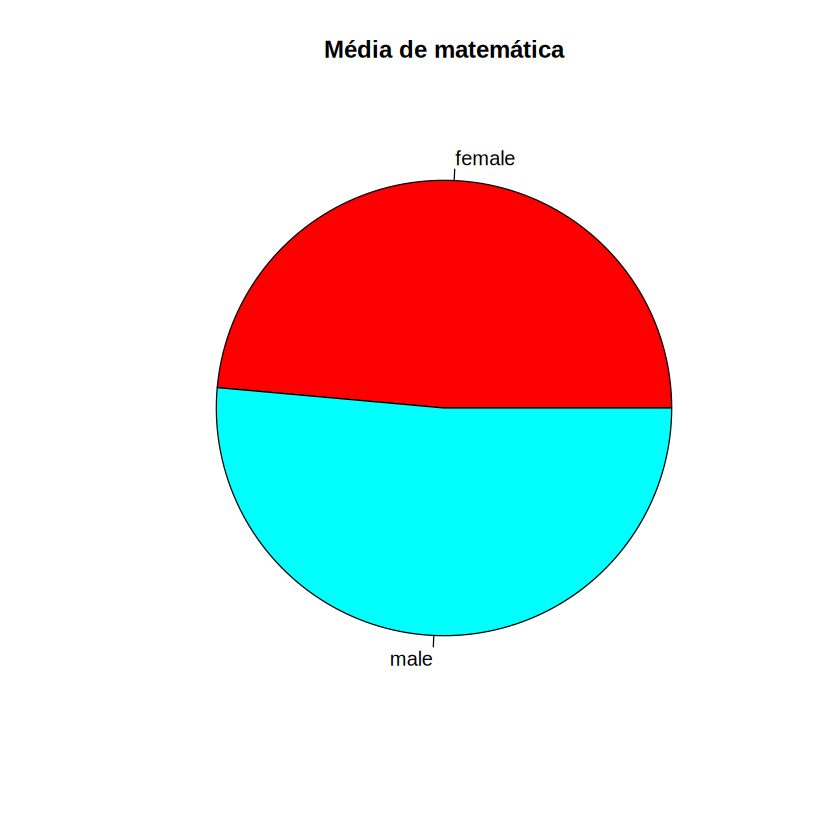

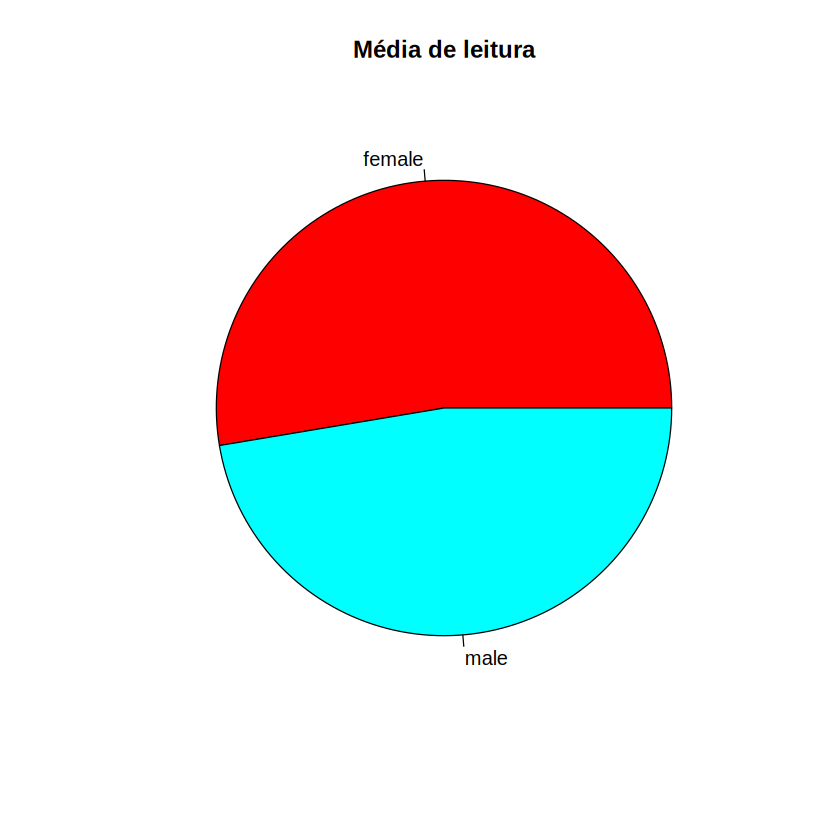

gender,media_math,media_reading,media_writing
<chr>,<dbl>,<dbl>,<dbl>
female,64.30198,72.32840,71.92359
male,68.07408,65.08431,63.23730


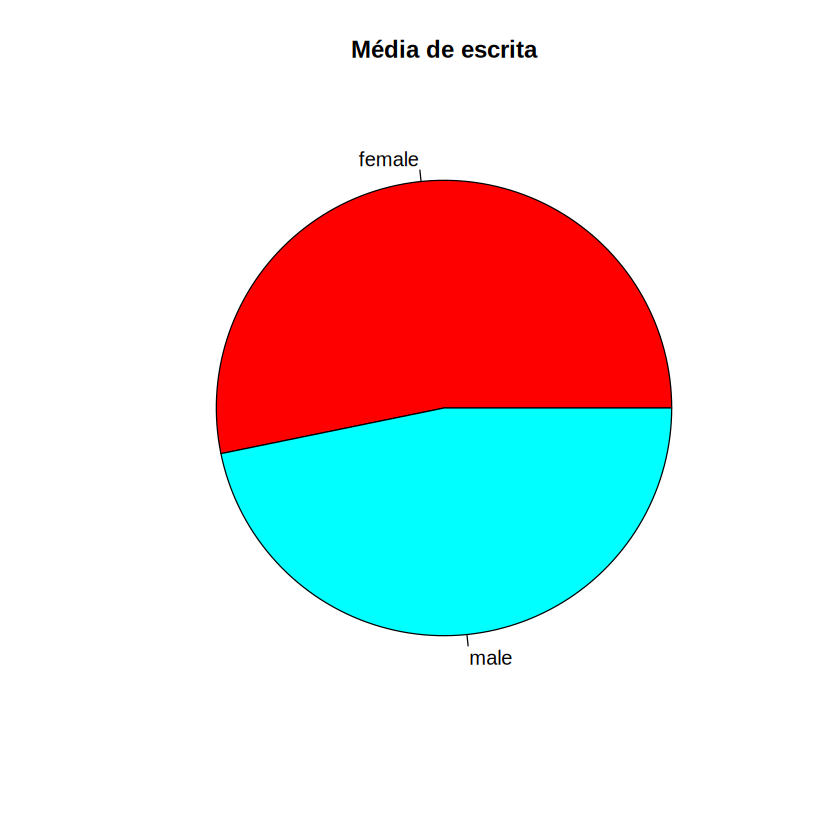

In [101]:
genero <- table %>% group_by(gender) %>%
summarize(
media_math = mean(math.score), #media em R
media_reading = mean(reading.score),
media_writing = mean(writing.score)
)

pie( #gráfico
  genero$media_math,
  labels = genero$gender,
  col = rainbow(length(genero$gender)),
  main = "Média de matemática"
)
pie(
  genero$media_reading,
  labels = genero$gender,
  col = rainbow(length(genero$gender)),
  main = "Média de leitura"
)
pie(
  genero$media_writing,
  labels = genero$gender,
  col = rainbow(length(genero$gender)),
  main = "Média de escrita"
)
View(genero)


In [115]:
nivel_escolaridade <- table %>% distinct(parental.level.of.education)

View(nivel_escolaridade)

parental.level.of.education
<chr>
bachelor's degree
some college
master's degree
associate's degree
high school
some high school


In [121]:
media.nivel_escolaridade <- table %>% group_by(parental.level.of.education) %>%
  summarise(
  media.math = round(mean(math.score),2), #round - quantidade de casas decimais
  media_reading = round(mean(reading.score),2),
  media_writing = round(mean(writing.score),2)
  )
  View(media.nivel_escolaridade)

parental.level.of.education,media.math,media_reading,media_writing
<chr>,<dbl>,<dbl>,<dbl>
associate's degree,67.36,70.75,69.78
bachelor's degree,69.35,73.15,72.25
high school,62.90,65.17,63.01
master's degree,69.95,74.48,76.05
some college,66.45,68.52,68.05
some high school,63.24,66.85,65.18


In [132]:
alunos.race.ethnicity <- table %>% distinct(sort(race.ethnicity))
View(alunos.race.ethnicity)

sort(race.ethnicity)
<chr>
group a
group b
group c
group d
group e


race.ethnicity,quantidade,quantidade_porcentagem
<chr>,<int>,<dbl>
group a,88,8.63
group b,183,17.94
group c,354,34.71
group d,258,25.29
group e,137,13.43


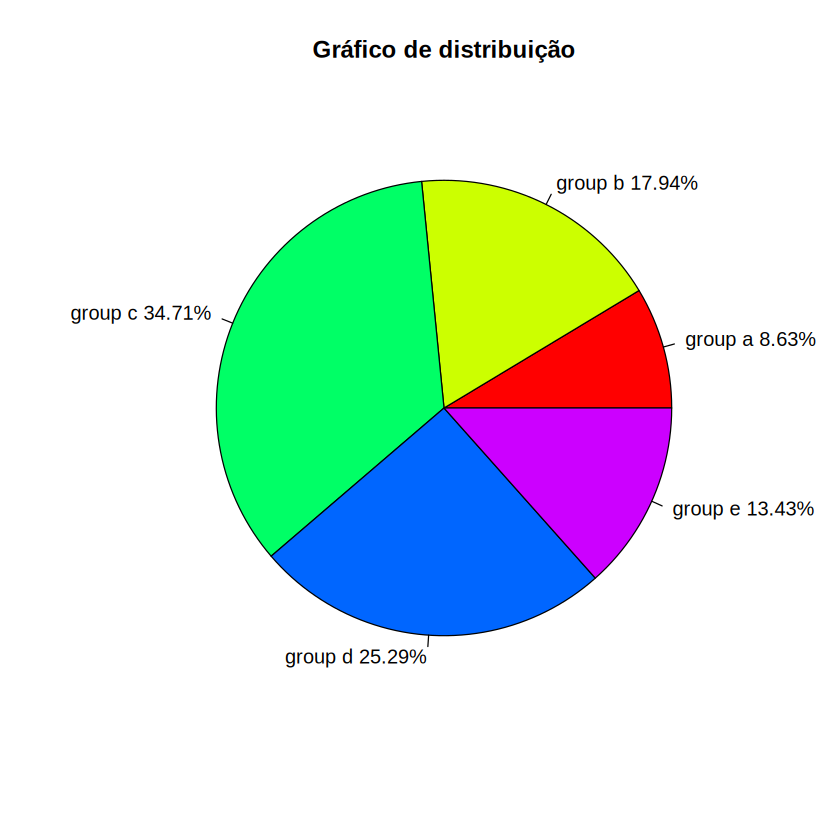

In [169]:
#5
quant.p.categoria <- table %>%
  group_by(race.ethnicity) %>%
  summarise(
    quantidade = n(),
    quantidade_porcentagem = round((n() / nrow(table) * 100), 2)
  )
rotulos <- paste(quant.p.categoria$race.ethnicity, paste0(quant.p.categoria$quantidade_porcentagem, "%")) #texto de categoria e sinal de %(paste0()"%")

pie(
  quant.p.categoria$quantidade_porcentagem,
  labels = rotulos,
  col = rainbow(length(quant.p.categoria$race.ethnicity)),
  main = "Gráfico de distribuição"
)

View(quant.p.categoria)

test.preparation.course,media_matematica,media_leitura,media_escrita
<chr>,<dbl>,<dbl>,<dbl>
completed,69.20,73.73,74.39
none,64.38,66.69,64.76


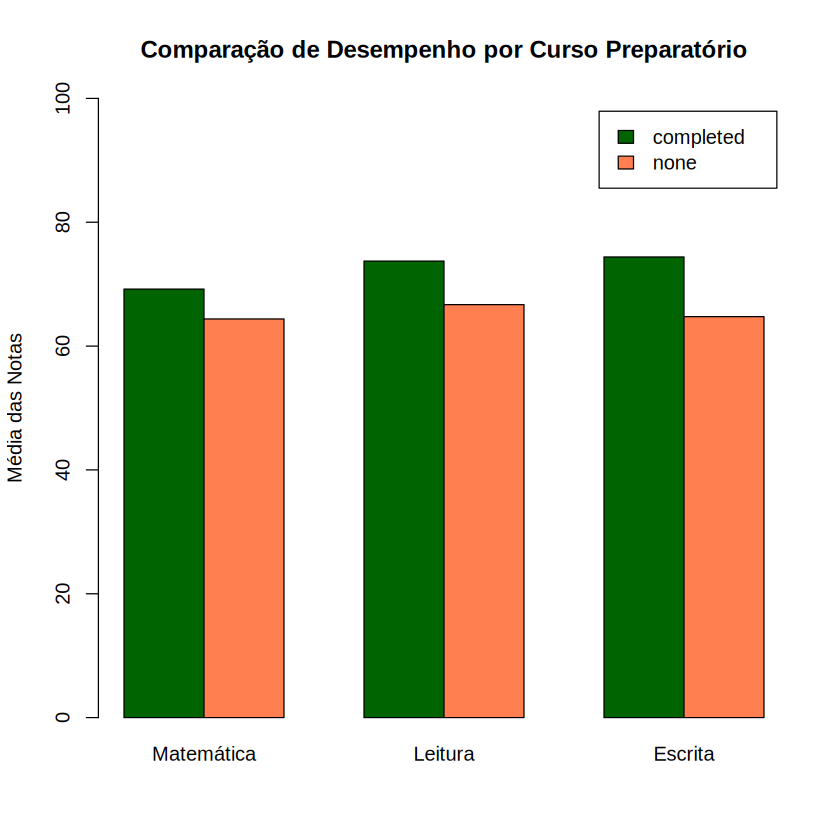

In [172]:
#6 e 7
comparacao_preparatorio <- table %>%
  group_by(test.preparation.course) %>%
  summarise(
    media_matematica = round(mean(math.score), 2),
    media_leitura = round(mean(reading.score), 2),
    media_escrita = round(mean(writing.score), 2)
  )

# 2. Converte as colunas numéricas em matriz para o barplot
matriz_medias <- as.matrix(comparacao_preparatorio[, c("media_matematica", "media_leitura", "media_escrita")])
rownames(matriz_medias) <- comparacao_preparatorio$test.preparation.course

# 3. Gráfico de barras lado a lado
barplot(
  matriz_medias,
  beside = TRUE,
  col = c("darkgreen", "coral"),
  legend.text = rownames(matriz_medias),
  main = "Comparação de Desempenho por Curso Preparatório",
  names.arg = c("Matemática", "Leitura", "Escrita"),
  ylab = "Média das Notas",
  ylim = c(0, 100)
)

View(comparacao_preparatorio)